In [7]:
from roboflow import Roboflow

rf = Roboflow(api_key="Dq0wTfBgTno8oRiyCPgn")

veri_setleri = [
    {"workspace": "soiltechai", "project": "tomato-crop", "version": 1},
    {"workspace": "selada-ojtld", "project": "lettuce-j9wu0", "version": 1},
    {"workspace": "yolov5plantdoc", "project": "kaggle-healthy-strawberry-leaf", "version": 1},
    {"workspace": "project-3jgqn", "project": "leaf-segmentation-wgh17", "version": 2},
    {"workspace": "vegetable-status", "project": "vegetable-status-jkngd", "version": 1},
    {"workspace": "roboinference", "project": "pepper-video", "version": 1} # Biber
]

print("Veri seti indirme işlemi başlatılıyor...\n" + "-"*40)

for ds in veri_setleri:
    try:
        print(f"İndiriliyor: {ds['project']}...")
        project = rf.workspace(ds["workspace"]).project(ds["project"])
        dataset = project.version(ds["version"]).download("yolov8")
        print(f"BAŞARILI: {ds['project']} klasöre eklendi!\n")
    except Exception as e:
        print(f"HATA ({ds['project']}): {e}\n")

print("Tüm indirme işlemleri tamamlandı.")

Veri seti indirme işlemi başlatılıyor...
----------------------------------------
İndiriliyor: tomato-crop...
loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 92.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to Tomato-Crop-1 in yolov8:: 100%|██████████| 4005/4005 [00:01<00:00, 2421.65it/s]

BAŞARILI: tomato-crop klasöre eklendi!

İndiriliyor: lettuce-j9wu0...
loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to lettuce-1 in yolov8:: 100%|██████████| 19622/19622 [00:08<00:00, 2310.77it/s]


...


Extracting Dataset Version Zip to Vegetable-Status-1 in yolov8:: 100%|██████████| 668/668 [00:00<00:00, 2704.29it/s]

BAŞARILI: vegetable-status-jkngd klasöre eklendi!

İndiriliyor: pepper-video...
loading Roboflow workspace...


loading Roboflow project...
Exporting format yolov8 in progress : 0.1%
Version export complete for yolov8 format



Extracting Dataset Version Zip to Pepper-video-1 in yolov8:: 100%|██████████| 57/57 [00:00<00:00, 2374.77it/s]

BAŞARILI: pepper-video klasöre eklendi!

Tüm indirme işlemleri tamamlandı.


In [8]:
import os
import shutil
import glob

hedef_klasor = "Master-Dataset"
bolumler = ["train", "valid", "test"]

for b in bolumler:
    os.makedirs(f"{hedef_klasor}/{b}/images", exist_ok=True)
    os.makedirs(f"{hedef_klasor}/{b}/labels", exist_ok=True)

toplam_resim = 0

klasorler = [d for d in os.listdir('.') if os.path.isdir(d) and os.path.exists(os.path.join(d, 'data.yaml')) and d != hedef_klasor]

for klasor in klasorler:
    for kaynak_b in ["train", "valid", "val", "test"]:
        hedef_b = "valid" if kaynak_b == "val" else kaynak_b
        if hedef_b not in bolumler: continue

        resimler = glob.glob(f"{klasor}/{kaynak_b}/images/*.*")
        for resim_yolu in resimler:
            dosya_adi = os.path.basename(resim_yolu)
            etiket_adi = os.path.splitext(dosya_adi)[0] + ".txt"
            etiket_yolu = f"{klasor}/{kaynak_b}/labels/{etiket_adi}"

            if os.path.exists(etiket_yolu):
                shutil.copy(resim_yolu, f"{hedef_klasor}/{hedef_b}/images/{dosya_adi}")

                with open(etiket_yolu, "r") as f_oku:
                    satirlar = f_oku.readlines()

                with open(f"{hedef_klasor}/{hedef_b}/labels/{etiket_adi}", "w") as f_yaz:
                    for satir in satirlar:
                        parcalar = satir.strip().split()
                        if len(parcalar) > 4:
                            parcalar[0] = "0"
                            f_yaz.write(" ".join(parcalar) + "\n")
                toplam_resim += 1

yaml_icerik = f"""path: {os.path.abspath(hedef_klasor).replace(os.sep, '/')}
train: train/images
val: valid/images
test: test/images

names:
- yaprak
nc: 1
"""
with open(f"{hedef_klasor}/data.yaml", "w") as f:
    f.write(yaml_icerik)

print(f"Toplam {toplam_resim} adet fotoğraf ve etiket başarıyla birleştirildi.")
print(f"Tüm veriler 'Master-Dataset' klasörüne aktarıldı ve tek bir 'yaprak' sınıfına dönüştürüldü.")

Toplam 13205 adet fotoğraf ve etiket başarıyla birleştirildi.
Tüm veriler 'Master-Dataset' klasörüne aktarıldı ve tek bir 'yaprak' sınıfına dönüştürüldü.


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n-seg.pt")

results = model.train(
    data="Master-Dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    name="biyokutle_segmentasyon"
)

New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.176  Python-3.14.3 torch-2.14.1+cpu CPU (AMD Ryzen 7 7840HS w/ Radeon 780M Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Master-Dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-s

In [1]:
import torch
print(torch.cuda.is_available())

True


In [3]:
from ultralytics import YOLO

model = YOLO("yolov8n-seg.pt")

results = model.train(
    data="Master-Dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    name="biyokutle_gpu_run"
)

Ultralytics 8.4.177  Python-3.12.9 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Master-Dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=biyokutle_gpu_run, nbs=64, nms=None


[lettuce-1/valid/images\-1-_jpg.rf.61ef146761dd50339c816fbf625c0d4a.jpg] isleniyor...

image 1/1 C:\Users\iclalolukkaya\PycharmProjects\BiyokutleBuyumeTakibi\notebooks\lettuce-1\valid\images\-1-_jpg.rf.61ef146761dd50339c816fbf625c0d4a.jpg: 640x640 5 yapraks, 96.8ms
Speed: 5.7ms preprocess, 96.8ms inference, 56.8ms postprocess per image at shape (1, 3, 640, 640)
🌿 Toplam Yaprak Biyokütle Alanı: 280749 Piksel


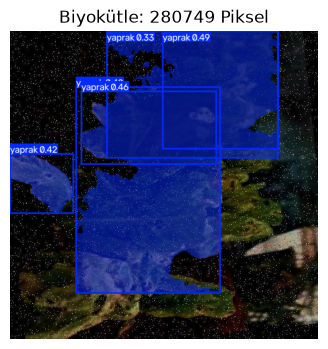


[lettuce-1/valid/images\-3-_jpg.rf.2fc6d57ece4737554437e6a1d332b4d5.jpg] isleniyor...

image 1/1 C:\Users\iclalolukkaya\PycharmProjects\BiyokutleBuyumeTakibi\notebooks\lettuce-1\valid\images\-3-_jpg.rf.2fc6d57ece4737554437e6a1d332b4d5.jpg: 640x640 1 yaprak, 7.6ms
Speed: 1.1ms preprocess, 7.6ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 640)
🌿 Toplam Yaprak Biyokütle Alanı: 277338 Piksel


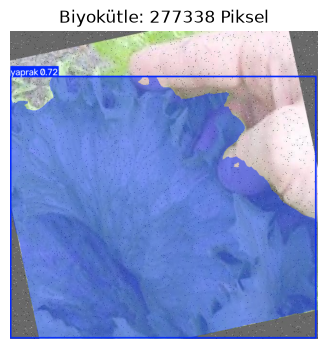


[lettuce-1/valid/images\-3-_jpg.rf.58db84a1c1c2de19f4292fbb4bf3e9b0.jpg] isleniyor...

image 1/1 C:\Users\iclalolukkaya\PycharmProjects\BiyokutleBuyumeTakibi\notebooks\lettuce-1\valid\images\-3-_jpg.rf.58db84a1c1c2de19f4292fbb4bf3e9b0.jpg: 640x640 2 yapraks, 8.0ms
Speed: 1.1ms preprocess, 8.0ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
🌿 Toplam Yaprak Biyokütle Alanı: 309034 Piksel


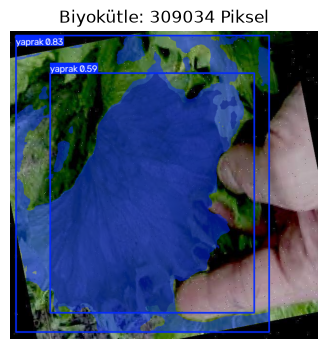

In [3]:
from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob

model = YOLO("../sera_model_best.pt")

resim_listesi = glob.glob("lettuce-1/valid/images/*.jpg")[:3]

for resim_yolu in resim_listesi:
    print(f"\n[{resim_yolu}] isleniyor...")

    sonuclar = model.predict(source=resim_yolu, conf=0.25, save=False)

    for sonuc in sonuclar:
        if sonuc.masks is not None:
            maskeler = sonuc.masks.data.cpu().numpy()
            toplam_piksel_alani = 0

            for maske in maskeler:
                yaprak_pikselleri = np.sum(maske == 1)
                toplam_piksel_alani += yaprak_pikselleri

            print("="*40)
            print(f"🌿 Toplam Yaprak Biyokütle Alanı: {toplam_piksel_alani} Piksel")
            print("="*40)

            cizimli_resim = sonuc.plot()
            plt.figure(figsize=(8, 4))
            plt.imshow(cv2.cvtColor(cizimli_resim, cv2.COLOR_BGR2RGB))
            plt.axis("off")
            plt.title(f"Biyokütle: {toplam_piksel_alani} Piksel")
            plt.show()
        else:
            print("⚠️ Bu fotoğrafta yaprak tespit edilemedi (Boş resim olabilir).")


image 1/1 C:\Users\iclalolukkaya\PycharmProjects\BiyokutleBuyumeTakibi\notebooks\lettuce-1\valid\images\-1-_jpg.rf.61ef146761dd50339c816fbf625c0d4a.jpg: 640x640 5 yapraks, 70.1ms
Speed: 5.5ms preprocess, 70.1ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)
🌿 Gün 1 Ölçülen Biyokütle Alanı: 280749 Piksel

image 1/1 C:\Users\iclalolukkaya\PycharmProjects\BiyokutleBuyumeTakibi\notebooks\lettuce-1\valid\images\-3-_jpg.rf.2fc6d57ece4737554437e6a1d332b4d5.jpg: 640x640 1 yaprak, 8.1ms
Speed: 1.4ms preprocess, 8.1ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)
🌿 Gün 2 Ölçülen Biyokütle Alanı: 277338 Piksel

image 1/1 C:\Users\iclalolukkaya\PycharmProjects\BiyokutleBuyumeTakibi\notebooks\lettuce-1\valid\images\-3-_jpg.rf.58db84a1c1c2de19f4292fbb4bf3e9b0.jpg: 640x640 2 yapraks, 9.1ms
Speed: 1.2ms preprocess, 9.1ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)
🌿 Gün 3 Ölçülen Biyokütle Alanı: 309034 Piksel

image 1/1 C:\Users\iclalolukkaya

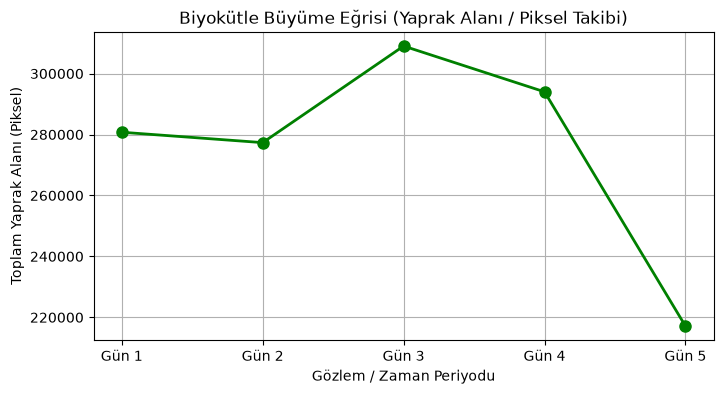

In [4]:
from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob

model = YOLO("../sera_model_best.pt")

resim_listesi = sorted(glob.glob("lettuce-1/valid/images/*.jpg"))[:5]

gunler = []
biyokutle_pikselleri = []

for i, resim_yolu in enumerate(resim_listesi):
    sonuclar = model.predict(source=resim_yolu, conf=0.25, save=False)

    toplam_piksel_alani = 0
    for sonuc in sonuclar:
        if sonuc.masks is not None:
            maskeler = sonuc.masks.data.cpu().numpy()
            for maske in maskeler:
                toplam_piksel_alani += np.sum(maske == 1)

    gunler.append(f"Gün {i+1}")
    biyokutle_pikselleri.append(toplam_piksel_alani)
    print(f"🌿 Gün {i+1} Ölçülen Biyokütle Alanı: {toplam_piksel_alani} Piksel")

plt.figure(figsize=(8, 4))
plt.plot(gunler, biyokutle_pikselleri, marker='o', color='green', linestyle='-', linewidth=2, markersize=8)
plt.title("Biyokütle Büyüme Eğrisi (Yaprak Alanı / Piksel Takibi)")
plt.xlabel("Gözlem / Zaman Periyodu")
plt.ylabel("Toplam Yaprak Alanı (Piksel)")
plt.grid(True)
plt.show()

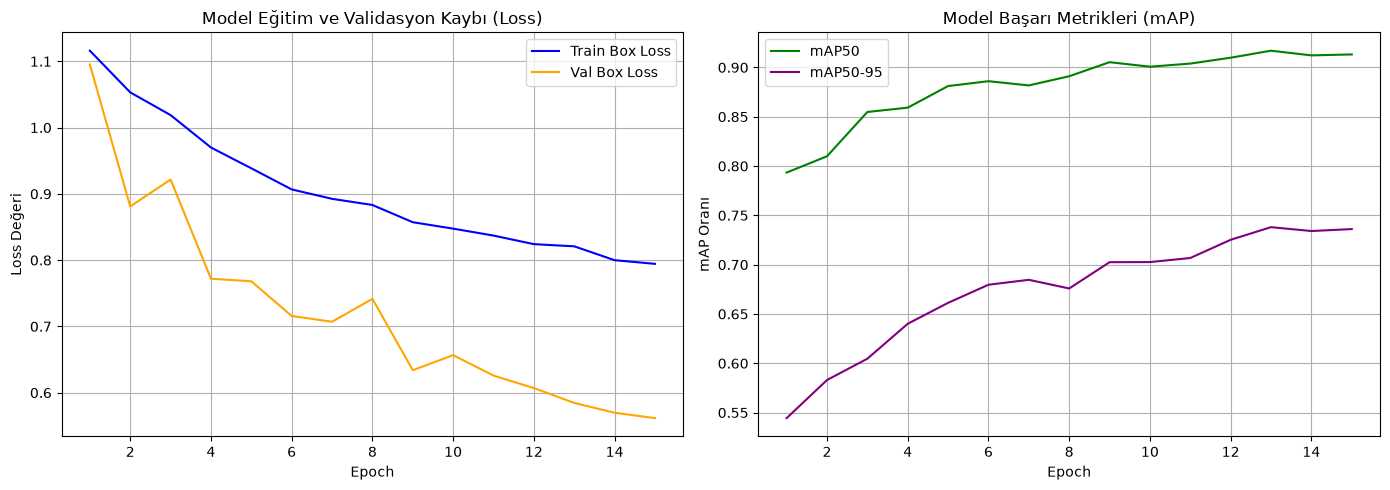

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

csv_yolu = "../runs/segment/biyokutle_segmentasyon/results.csv"

df = pd.read_csv(csv_yolu)
df.columns = df.columns.str.strip()

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
if 'train/box_loss' in df.columns:
    plt.plot(df['epoch'], df['train/box_loss'], label='Train Box Loss', color='blue')
if 'val/box_loss' in df.columns:
    plt.plot(df['epoch'], df['val/box_loss'], label='Val Box Loss', color='orange')
plt.title("Model Eğitim ve Validasyon Kaybı (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss Değeri")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
if 'metrics/mAP50(B)' in df.columns:
    plt.plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP50', color='green')
if 'metrics/mAP50-95(B)' in df.columns:
    plt.plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP50-95', color='purple')
plt.title("Model Başarı Metrikleri (mAP)")
plt.xlabel("Epoch")
plt.ylabel("mAP Oranı")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()